# Lab 6 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It imports your finished functions from `../src/lab06.py` and plots their output.
One cell (the forecast reconstruction) asks you to re-run your own Task 4 steps to get
the actual predictions — if a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the reconstruction cell and the three plot cells, then **export each
figure and paste it into `report.pdf`** (right-click → Save image as…, or
`plt.savefig('fig1.png', dpi=150)`). Report figures 1–3 are required by the report template.


In [1]:
import sys
sys.path.insert(0, '../src')
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import lab06

series = lab06.load_data('../data/cafe_daily.csv')
results = lab06.run_experiment(series)
results

{'n_train': 739,
 'n_val': 150,
 'n_test': 150,
 'scale_mean': 170.4754,
 'scale_std': 25.5496,
 'naive_scale': 16.2314,
 'persistence': {'mae': 15.5067, 'rmse': 20.0934, 'mase': 0.9554},
 'rnn': {'mae': 9.2921, 'rmse': 11.6667, 'mase': 0.5725}}

In [2]:
# ============ TODO (forecast reconstruction) ============
# run_experiment returns only the metrics; the plots need the actual test-set
# forecasts. Rebuild them here with the SAME steps as your run_experiment
# (its docstring, steps 1–8): seed, chronological split, scaler fitted on the
# training segment ONLY, windows, train the RNN, predict, de-normalise.
#
# Produce exactly these four variables for the plot cells below:
#   y_true            test targets, de-normalised back to cups
#   pred_rnn          your RNN's test predictions, de-normalised
#   pred_persistence  the persistence forecast (last window value), de-normalised
#   test_days         position of each test target in the original series
#
# If your run_experiment is correct, this cell is a re-arrangement of code you
# have already written in src/lab06.py — nothing new.
lab06.set_seed()
train_idx, val_idx, test_idx = lab06.temporal_split(len(series))
mean = float(np.mean(series[train_idx]))
std = float(np.std(series[train_idx]))

X_train, y_train = lab06.make_windows((series[train_idx]-mean) / std, lab06.WINDOW, lab06.HORIZON)
X_val, y_val = lab06.make_windows((series[val_idx]-mean) / std, lab06.WINDOW, lab06.HORIZON)
X_test, y_test = lab06.make_windows((series[test_idx]-mean) / std, lab06.WINDOW, lab06.HORIZON)

model, _ = lab06.train_model(lab06.build_rnn(), X_train, y_train, X_val, y_val)

y_true = y_test * std + mean
pred_rnn = lab06.predict(model, X_test) * std + mean
pred_persistence = X_test[:, -1] * std + mean
test_days = test_idx[lab06.WINDOW + lab06.HORIZON - 1:]
# ========================================================


## Report figure 1 — the series and the chronological split

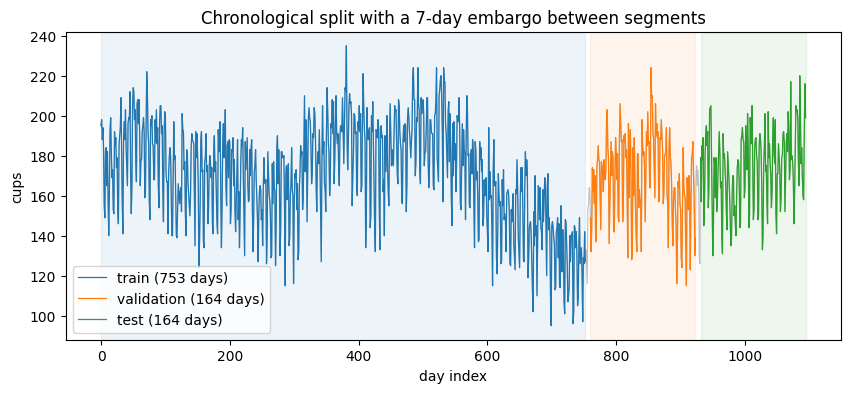

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(series, color='0.75', linewidth=0.8)
for idx, name, color in ((train_idx, 'train', 'tab:blue'),
                         (val_idx, 'validation', 'tab:orange'),
                         (test_idx, 'test', 'tab:green')):
    ax.plot(idx, series[idx], color=color, linewidth=0.9, label=f'{name} ({len(idx)} days)')
    ax.axvspan(idx[0], idx[-1], color=color, alpha=0.08)
ax.set_xlabel('day index')
ax.set_ylabel('cups')
ax.set_title(f'Chronological split with a {lab06.GAP}-day embargo between segments')
ax.legend()
plt.savefig('fig1.png', dpi=150, bbox_inches='tight')
plt.show()

## Report figure 2 — forecasts on the test segment

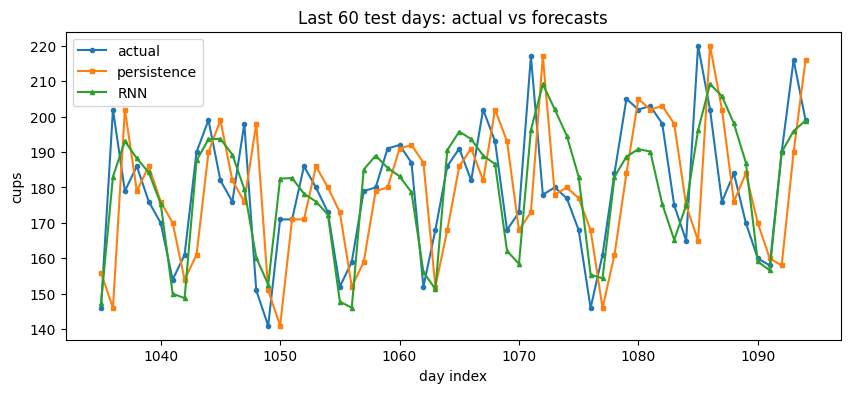

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(test_days[-60:], y_true[-60:], marker='o', ms=3, label='actual')
ax.plot(test_days[-60:], pred_persistence[-60:], marker='s', ms=3, label='persistence')
ax.plot(test_days[-60:], pred_rnn[-60:], marker='^', ms=3, label='RNN')
ax.set_xlabel('day index')
ax.set_ylabel('cups')
ax.set_title('Last 60 test days: actual vs forecasts')
ax.legend()
plt.savefig('fig2.png', dpi=150, bbox_inches='tight')
plt.show()

## Report figure 3 — error comparison

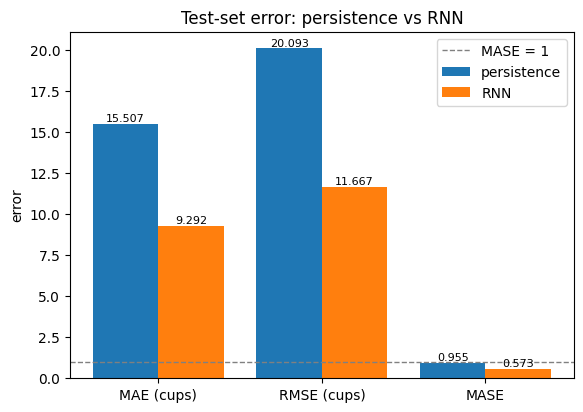

In [5]:
labels = ['mae', 'rmse', 'mase']
x = np.arange(3)
p = [results['persistence'][k] for k in labels]
r = [results['rnn'][k] for k in labels]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(x-0.2, p, width=0.4, label='persistence')
ax.bar(x+0.2, r, width=0.4, label='RNN')
ax.axhline(1.0, linestyle='--', color='gray', linewidth=1, label='MASE = 1')
ax.set_xticks(x)
ax.set_xticklabels(['MAE (cups)', 'RMSE (cups)', 'MASE'])
ax.set_ylabel('error')
ax.set_title('Test-set error: persistence vs RNN')
ax.legend()
for i in range(3):
    ax.text(x[i]-0.2, p[i], f'{p[i]:.3f}', ha='center', va='bottom', fontsize=8)
    ax.text(x[i]+0.2, r[i], f'{r[i]:.3f}', ha='center', va='bottom', fontsize=8)
plt.savefig('fig3.png', dpi=150, bbox_inches='tight')
plt.show()